# 02 · Análise Exploratória de Dados (EDA)
**Projeto 01 – Agente inteligente de rotas para distribuição de produtos locais**

**Grupo:** G11 · **Elementos:** Afonso Macedo (nº31554), Rafael Matos 2 (nº39343), Henrique Ribeiro 3 (nº29325), Diogo Rocha 4 (nº29339)

## Objetivo
Antes de construir o agente que planeia as rotas, é preciso **conhecer e validar os dados**. Este notebook analisa o dataset *tiny* e responde a cinco perguntas:

1. Que dados temos e como estão organizados? *(secção 1)*
2. Os dados estão corretos e consistentes? *(secção 2)*
3. Que pedidos existem e que janelas temporais têm? *(secção 3)*
4. Os veículos têm capacidade para transportar o que é pedido? *(secção 4)*
5. Onde ficam as paragens? *(secção 5)*

Na secção 6 resumimos as conclusões e o que o modelo do agente tem de ter em conta.

**Como ler este notebook:** cada análise tem um texto a explicar *o que vamos fazer e porquê*, o código, e um texto com *o que concluímos*.

## 1. Carregar os dados

Nesta secção carregamos todos os ficheiros CSV do dataset para memória e fazemos um primeiro resumo. O objetivo é perceber **quantos dados temos** e **para que serve cada ficheiro**.

### 1.1 Preparar o ambiente
Importamos as bibliotecas necessárias (pandas para tabelas, numpy para cálculo e matplotlib para gráficos) e definimos o caminho para a pasta `data_tiny/`, que contém os ficheiros CSV com os dados do problema. Como este notebook está na pasta `notebooks/`, o caminho é definido de forma relativa (`../data_tiny/`).

In [ ]:
import os, zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

DATA_DIR = "../data_tiny/"        # mudar para "data_large/" para o dataset maior

# --- Google Colab: se a pasta ainda não existir, pede o zip ---------------------
if not os.path.exists(DATA_DIR):
    try:
        from google.colab import files
        print("Escolha o ficheiro data_tiny.zip")
        up = files.upload()
        zname = next(iter(up))
        zipfile.ZipFile(zname).extractall(".")
    except ImportError:
        raise FileNotFoundError(f"Pasta {DATA_DIR} não encontrada")
print("Ficheiros:", sorted(os.listdir(DATA_DIR)))

Ficheiros: ['collection_centers.csv', 'customers.csv', 'delivery_locations.csv', 'distance_matrix.csv', 'localities.csv', 'locations.csv', 'order_items.csv', 'orders.csv', 'producers.csv', 'products.csv', 'vehicles.csv']


### 1.2 Ler os ficheiros e fazer um resumo
Lemos os 11 ficheiros CSV para um dicionário `dfs` (por exemplo, `dfs["vehicles"]` é a tabela de veículos). Convertemos também as colunas de datas, que vêm como texto, para o formato de data/hora, para podermos compará-las e fazer contas com elas.

Depois construímos uma tabela-resumo com o número de linhas e colunas de cada ficheiro, e quantos **valores nulos** (células vazias) e **linhas duplicadas** tem.

In [ ]:
NAMES = ["localities", "locations", "producers", "products", "collection_centers",
         "customers", "delivery_locations", "vehicles", "orders", "order_items",
         "distance_matrix"]

# lê cada CSV e guarda-o num dicionário: dfs["vehicles"], dfs["orders"], ...
dfs = {n: pd.read_csv(f"{DATA_DIR}{n}.csv") for n in NAMES}

# converte as colunas de datas de texto para data/hora
for c in ["availability_start", "availability_end", "delivery_start", "delivery_end"]:
    dfs["order_items"][c] = pd.to_datetime(dfs["order_items"][c])
dfs["orders"]["order_datetime"] = pd.to_datetime(dfs["orders"]["order_datetime"])

print(f"✔ {len(dfs)} ficheiros carregados")

✔ 11 ficheiros carregados


In [ ]:
summary = pd.DataFrame({
    n: {"linhas": len(d), "colunas": d.shape[1],
        "nulos": int(d.isna().sum().sum()), "duplicados": int(d.duplicated().sum())}
    for n, d in dfs.items()}).T
summary

,linhas,colunas,nulos,duplicados
localities,49,6,0,0
locations,12,7,0,0
producers,5,6,0,0
products,23,6,0,0
collection_centers,1,5,0,0
customers,8,5,0,0
delivery_locations,6,5,0,0
vehicles,2,6,0,0
orders,10,5,0,0
order_items,23,8,0,0


**O que vemos:** Os 11 ficheiros carregam sem problemas e **não há valores nulos nem linhas duplicadas** em nenhuma tabela. O dataset *tiny* é pequeno: 23 itens de encomenda (`order_items`), 10 encomendas, 2 veículos, 49 localidades e uma matriz de distâncias com 132 linhas. Isto permite validar tudo com facilidade e depurar os algoritmos sem esperas.

**Para que serve cada ficheiro:**

| Ficheiro | Conteúdo |
|---|---|
| `localities` | locais geográficos (freguesia/concelho/distrito + coordenadas) |
| `producers`, `products` | produtores e os produtos que vendem (com peso unitário) |
| `collection_centers`, `vehicles` | armazém e frota (capacidade, velocidade) |
| `customers`, `delivery_locations` | clientes e locais de entrega |
| `orders`, `order_items` | encomendas e os seus itens, **com as janelas temporais** |
| `locations` | todas as paragens possíveis, com um `location_id` único |
| `distance_matrix` | distância (km) e tempo (min) entre cada par de `location_id` |

### 1.3 Espreitar as tabelas principais
Mostramos as primeiras linhas das 5 tabelas mais importantes para o problema: os veículos, os produtos, as encomendas, os itens das encomendas e as paragens (`locations`). Serve para ver que colunas existem e como são os valores.

In [ ]:
for n in ["vehicles", "products", "orders", "order_items", "locations"]:
    print(f"--- {n} ---")
    display(dfs[n].head(5))

--- vehicles ---


,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,1444.7,0,57.8
1,2,TY-74-YA,1,1009.8,0,59.5


--- products ---


,product_id,producer_id,name,category,unit,unit_weight_kg
0,1,1,Batata,vegetable,kg,1.0
1,2,1,Uva,fruit,kg,1.0
2,3,1,Limao,fruit,kg,1.0
3,4,1,Nabo,vegetable,kg,1.0
4,5,1,Kiwi,fruit,kg,1.0


--- orders ---


,order_id,customer_id,delivery_location_id,order_datetime,status
0,1,5,6,2026-10-15 10:45:00,placed
1,2,6,6,2026-10-17 13:00:00,confirmed
2,3,1,4,2026-10-10 12:00:00,placed
3,4,3,2,2026-10-15 10:30:00,confirmed
4,5,4,5,2026-10-08 11:30:00,confirmed


--- order_items ---


,order_item_id,order_id,product_id,quantity,availability_start,availability_end,delivery_start,delivery_end
0,1,1,1,14.1,2026-10-13 08:00:00,2026-10-13 11:00:00,2026-10-13 13:00:00,2026-10-13 17:00:00
1,2,1,8,17.2,2026-10-17 12:45:00,2026-10-17 15:45:00,2026-10-18 13:45:00,2026-10-18 17:45:00
2,3,2,7,11.0,2026-10-07 09:00:00,2026-10-07 11:00:00,2026-10-07 12:00:00,2026-10-07 14:00:00
3,4,2,9,5.1,2026-10-09 07:00:00,2026-10-09 13:00:00,2026-10-09 12:00:00,2026-10-09 16:00:00
4,5,3,19,1.4,2026-10-10 10:00:00,2026-10-10 15:00:00,2026-10-10 15:00:00,2026-10-10 19:00:00


--- locations ---


,location_id,location_type,ref_id,name,municipality,latitude,longitude
0,1,producer,1,Hortas Valente,Fafe,41.463574,-8.159840
1,2,producer,2,Quinta Leite,Vieira do Minho,41.627980,-8.166483
2,3,producer,3,Quinta Morais,Guimaraes,41.464457,-8.297740
3,4,producer,4,Pomar Carvalho,Povoa de Varzim,41.398757,-8.765766
4,5,producer,5,Pomar Antunes,Fafe,41.463574,-8.159840


**O que vemos.**
- As tabelas ligam-se por identificadores: `order_items` aponta para `orders` e `products`, e `products` aponta para `producers`.
- `order_items` já traz as **quatro datas** de que o problema precisa (início e fim da recolha, início e fim da entrega), mas **não** traz o produtor nem o peso. Esses dados têm de ser obtidos juntando com `products`.
- `vehicles` indica a capacidade em kg e a velocidade média de cada veículo.
- `locations` dá um `location_id` a cada paragem (produtores, centro e locais de entrega) e as respetivas coordenadas.

## 2. Integridade dos dados

Antes de modelar, temos de ter a certeza de que os dados estão **consistentes**. Um erro aqui (por exemplo, uma encomenda que aponta para um produto que não existe) provocaria erros difíceis de encontrar mais tarde, nos algoritmos. Fazemos quatro verificações.

### 2.1 Chaves primárias únicas
Cada tabela tem uma coluna que identifica cada linha (o `id`). Tem de ser **única** (dois registos não podem ter o mesmo id) e **sem valores em falta**.

In [ ]:
PK = {"localities": "locality_id", "locations": "location_id", "producers": "producer_id",
      "products": "product_id", "collection_centers": "center_id",
      "customers": "customer_id", "delivery_locations": "delivery_location_id",
      "vehicles": "vehicle_id", "orders": "order_id", "order_items": "order_item_id"}

pk_check = pd.DataFrame([{"tabela": t, "chave": k, "únicas": dfs[t][k].is_unique,
                          "sem nulos": dfs[t][k].notna().all()} for t, k in PK.items()])
pk_check

,tabela,chave,únicas,sem nulos
0,localities,locality_id,True,True
1,locations,location_id,True,True
2,producers,producer_id,True,True
3,products,product_id,True,True
4,collection_centers,center_id,True,True
5,customers,customer_id,True,True
6,delivery_locations,delivery_location_id,True,True
7,vehicles,vehicle_id,True,True
8,orders,order_id,True,True
9,order_items,order_item_id,True,True


**Conclusão.** Todas as chaves primárias são únicas e sem nulos (`True` em todas as linhas). Podemos usar qualquer `id` como identificador de um objeto no modelo.

### 2.2 Chaves estrangeiras (as referências existem?)
Uma chave estrangeira é um `id` que aponta para outra tabela. Por exemplo, cada `order_items.product_id` tem de existir em `products`. Contamos os **"órfãos"**, isto é, as referências que não têm correspondência. O esperado é 0 em todas.

Verificamos também as ligações da tabela `locations` (cada paragem tem de corresponder a um produtor, centro ou local de entrega real) e da matriz de distâncias (origens e destinos têm de ser locais válidos).

In [ ]:
FK = [("customers", "locality_id", "localities", "locality_id"),
      ("producers", "locality_id", "localities", "locality_id"),
      ("collection_centers", "locality_id", "localities", "locality_id"),
      ("delivery_locations", "locality_id", "localities", "locality_id"),
      ("products", "producer_id", "producers", "producer_id"),
      ("orders", "customer_id", "customers", "customer_id"),
      ("orders", "delivery_location_id", "delivery_locations", "delivery_location_id"),
      ("order_items", "order_id", "orders", "order_id"),
      ("order_items", "product_id", "products", "product_id"),
      ("vehicles", "center_id", "collection_centers", "center_id")]

rows = []
for child, col, parent, pcol in FK:
    orphans = ~dfs[child][col].isin(dfs[parent][pcol])
    rows.append({"referência": f"{child}.{col} -> {parent}.{pcol}",
                 "órfãos": int(orphans.sum())})

# locations: cada (tipo, ref_id) tem de existir na tabela correspondente
TYPE_TABLE = {"producer": ("producers", "producer_id"),
              "collection_center": ("collection_centers", "center_id"),
              "delivery_location": ("delivery_locations", "delivery_location_id")}
loc = dfs["locations"]
for t, (tab, pk) in TYPE_TABLE.items():
    sub = loc[loc.location_type == t]
    rows.append({"referência": f"locations[{t}].ref_id -> {tab}.{pk}",
                 "órfãos": int((~sub.ref_id.isin(dfs[tab][pk])).sum())})

# distance_matrix: origens e destinos têm de ser location_id válidos
dm = dfs["distance_matrix"]
rows.append({"referência": "distance_matrix origem/destino -> locations.location_id",
             "órfãos": int((~dm.origin_location_id.isin(loc.location_id)).sum()
                           + (~dm.destination_location_id.isin(loc.location_id)).sum())})
pd.DataFrame(rows)

,referência,órfãos
0,customers.locality_id -> localities.locality_id,0
1,producers.locality_id -> localities.locality_id,0
2,collection_centers.locality_id -> localities.l...,0
3,delivery_locations.locality_id -> localities.l...,0
4,products.producer_id -> producers.producer_id,0
5,orders.customer_id -> customers.customer_id,0
6,orders.delivery_location_id -> delivery_locati...,0
7,order_items.order_id -> orders.order_id,0
8,order_items.product_id -> products.product_id,0
9,vehicles.center_id -> collection_centers.cente...,0


**Conclusão.** Há **0 órfãos** nas 14 verificações: todas as referências entre tabelas existem. Isto garante que as junções que vamos fazer (por exemplo, item → produto → produtor) não perdem linhas por falta de correspondência, e que todo o `location_id` da matriz de distâncias é uma paragem real.

*Nota:* esta célula cria as variáveis `loc` (tabela de paragens) e `dm` (matriz de distâncias), que as células seguintes usam.

### 2.3 Matriz de distâncias
A matriz diz quanto custa (em km e em minutos) ir de uma paragem a outra. É a base de todo o cálculo de rotas, por isso verificamos:
- tem **uma linha por cada par ordenado** de locais distintos (n·(n−1))?
- não tem pares repetidos, nem pares de um local para ele próprio, nem valores negativos?
- é **simétrica** (A→B custa o mesmo que B→A)?
- o tempo é coerente com uma velocidade média constante?

In [ ]:
n = loc.location_id.nunique()
print(f"Locais: {n} | linhas esperadas: {n*(n-1)} | linhas reais: {len(dm)}")
print("Pares duplicados:", int(dm.duplicated(["origin_location_id", "destination_location_id"]).sum()))
print("Auto-pares (i->i):", int((dm.origin_location_id == dm.destination_location_id).sum()))
print("Valores negativos:", int(((dm.distance_km < 0) | (dm.duration_min < 0)).sum()))

# simetria: a distância de A para B é igual à de B para A?
m = dm.set_index(["origin_location_id", "destination_location_id"])
rev = m.reindex(pd.MultiIndex.from_arrays([dm.destination_location_id, dm.origin_location_id]))
sym = np.allclose(m.distance_km.values, rev.distance_km.values) and \
      np.allclose(m.duration_min.values, rev.duration_min.values)
print("Matriz simétrica:", sym)

# velocidade implícita = km / horas
mask = dm.duration_min > 0
speed = dm.loc[mask, "distance_km"] / (dm.loc[mask, "duration_min"] / 60)
print(f"Velocidade implícita: min={speed.min():.1f} km/h, máx={speed.max():.1f} km/h")
print("Pares com distância 0:", dm[dm.distance_km == 0][["origin_location_id", "destination_location_id"]].values.tolist())

Locais: 12 | linhas esperadas: 132 | linhas reais: 132
Pares duplicados: 0
Auto-pares (i->i): 0
Valores negativos: 0
Matriz simétrica: True
Velocidade implícita: min=44.9 km/h, máx=45.1 km/h
Pares com distância 0: [[1, 5], [5, 1]]


**Conclusão.**
- A matriz tem as **132 linhas esperadas** (12·11), sem pares duplicados, sem auto-pares e sem valores negativos.
- É **simétrica**, o que simplifica os algoritmos: não precisamos de distinguir ir de ida ou de volta.
- A velocidade implícita é praticamente constante, cerca de **45 km/h**, por isso o tempo de viagem é proporcional à distância. Atenção: os veículos têm velocidades médias próprias (~58–60 km/h), por isso teremos de decidir no modelo qual usar.
- O único par com distância 0 é entre os locais 1 e 5, dois produtores com as mesmas coordenadas.

### 2.4 Desigualdade triangular
Ir diretamente de A até C nunca deve ser mais longo do que passar por B (A→B→C). Esta propriedade é importante: as **heurísticas** do A* e do Greedy somam distâncias diretas e só são **admissíveis** (nunca sobrestimam o custo real) se a desigualdade triangular se verificar. Testamos todos os trios de locais.

In [ ]:
# matriz de distâncias em formato tabela (linhas = origem, colunas = destino)
D = dm.pivot(index="origin_location_id", columns="destination_location_id",
             values="distance_km").fillna(0)
ids = list(D.index)

viol = 0
worst = 0.0
for a in ids:
    for b in ids:
        for c in ids:
            if len({a, b, c}) < 3:
                continue
            excess = D.loc[a, c] - (D.loc[a, b] + D.loc[b, c])
            if excess > 1e-6:
                viol += 1
                worst = max(worst, excess)
print(f"Violações da desigualdade triangular: {viol} (pior excesso: {worst:.3f} km)")

Violações da desigualdade triangular: 0 (pior excesso: 0.000 km)


**Conclusão.** Não há nenhuma violação: passar por um local intermédio nunca encurta o caminho. Logo, as heurísticas baseadas em distâncias diretas podem ser usadas no A* sem perder a garantia de admissibilidade.

## 3. Encomendas e janelas temporais

Cada linha de `order_items` é um **pedido**: recolher um produto num produtor, **dentro da sua janela de disponibilidade**, e entregá-lo a um cliente, **dentro da sua janela de entrega**. São estas janelas que tornam o problema difícil. Nesta secção vamos juntá-las com os restantes dados, validá-las e percebê-las.

### 3.1 Construir a tabela de pedidos
Os dados de cada pedido estão espalhados por várias tabelas. Juntamos tudo numa só tabela, `it`, com uma linha por pedido:
- de `products`: o produtor e o peso unitário;
- de `orders`: o local de entrega e o estado da encomenda;
- de `locations`: o `location_id` do produtor e do local de entrega (são os ids usados na matriz de distâncias);
- o **peso do pedido**, calculado como `quantidade × peso unitário`.

In [ ]:
# um item = um pedido de recolha + entrega
it = (dfs["order_items"]
      .merge(dfs["products"][["product_id", "name", "producer_id", "unit", "unit_weight_kg"]],
             on="product_id", how="left")
      .merge(dfs["orders"][["order_id", "customer_id", "delivery_location_id",
                            "order_datetime", "status"]],
             on="order_id", how="left"))

# location_id do produtor e do local de entrega (são os ids usados na matriz!)
prod_loc = loc[loc.location_type == "producer"].set_index("ref_id").location_id
deliv_loc = loc[loc.location_type == "delivery_location"].set_index("ref_id").location_id
it["pickup_loc"] = it.producer_id.map(prod_loc)
it["delivery_loc"] = it.delivery_location_id.map(deliv_loc)

# peso real do item = quantidade x peso unitário
it["weight_kg"] = it.quantity * it.unit_weight_kg

print("Itens:", len(it), "| Encomendas:", it.order_id.nunique())
it[["order_item_id", "order_id", "status", "product_id", "quantity", "weight_kg",
    "pickup_loc", "delivery_loc", "availability_start", "availability_end",
    "delivery_start", "delivery_end"]].head(8)

Itens: 23 | Encomendas: 10


,order_item_id,order_id,status,product_id,quantity,weight_kg,pickup_loc,delivery_loc,availability_start,availability_end,delivery_start,delivery_end
0,1,1,placed,1,14.1,14.1,1,12,2026-10-13 08:00:00,2026-10-13 11:00:00,2026-10-13 13:00:00,2026-10-13 17:00:00
1,2,1,placed,8,17.2,17.2,2,12,2026-10-17 12:45:00,2026-10-17 15:45:00,2026-10-18 13:45:00,2026-10-18 17:45:00
2,3,2,confirmed,7,11.0,13.2,2,12,2026-10-07 09:00:00,2026-10-07 11:00:00,2026-10-07 12:00:00,2026-10-07 14:00:00
3,4,2,confirmed,9,5.1,5.1,2,12,2026-10-09 07:00:00,2026-10-09 13:00:00,2026-10-09 12:00:00,2026-10-09 16:00:00
4,5,3,placed,19,1.4,1.4,4,10,2026-10-10 10:00:00,2026-10-10 15:00:00,2026-10-10 15:00:00,2026-10-10 19:00:00
5,6,3,placed,20,20.5,24.6,4,10,2026-10-20 10:30:00,2026-10-20 12:30:00,2026-10-20 12:30:00,2026-10-20 15:30:00
6,7,3,placed,19,21.1,21.1,4,10,2026-10-19 08:30:00,2026-10-19 13:30:00,2026-10-19 11:30:00,2026-10-19 12:30:00
7,8,3,placed,18,3.0,0.9,4,10,2026-10-12 12:45:00,2026-10-12 18:45:00,2026-10-12 13:45:00,2026-10-12 14:45:00


**O que vemos:** Temos 23 pedidos distribuídos por 10 encomendas, cada um com origem, destino, peso e quatro datas. Duas decisões importantes para o modelo:
1. O **peso** é `quantidade × peso unitário`, porque alguns produtos são vendidos à unidade e não ao quilo (ver secção 4).
2. Os locais usam `location_id`, que **não coincide** com `producer_id` nem com `delivery_location_id`. Confundir uns com os outros é um erro fácil de cometer e daria distâncias erradas.

### 3.2 Estado das encomendas
Cada encomenda tem um estado (`placed`, `confirmed` ou `delivered`). As que já foram entregues não precisam de rota, por isso vemos quantas são e quantos itens têm.

In [ ]:
display(dfs["orders"].status.value_counts().rename("encomendas").to_frame())
display(it.groupby("status").order_item_id.count().rename("itens").to_frame())
print("Itens por encomenda:", it.groupby("order_id").size().describe()[["min", "mean", "max"]].round(2).to_dict())

,encomendas
status,
placed,5
confirmed,4
delivered,1


,itens
status,
confirmed,9
delivered,3
placed,11


Itens por encomenda: {'min': 1.0, 'mean': 2.3, 'max': 4.0}


**O que vemos:** Das 10 encomendas, 5 estão `placed`, 4 `confirmed` e **1 já `delivered`** (3 itens). A encomenda já entregue não precisa de rota, por isso **fica fora do planeamento**: restam **20 pedidos** para o agente resolver (19, depois de retirar o pedido impossível que a secção 3.3 identifica). Cada encomenda tem em média cerca de 2 itens (entre 1 e 4).

### 3.3 Validação das janelas temporais
Verificamos se as janelas fazem sentido, com três regras sobre os 23 itens:
1. a janela de recolha começa **antes** de acabar;
2. a janela de entrega começa **antes** de acabar;
3. a entrega termina **depois** de a recolha começar.

Depois fazemos um teste mais exigente: cada item é possível **sozinho**? Como o produto **tem de passar pelo armazém** entre a recolha e a entrega, a viagem é produtor → armazém → cliente. Se o veículo recolher logo na abertura da janela e viajar sem esperas, chega a tempo? Um item que falhe aqui é impossível de cumprir.

In [ ]:
chk = pd.DataFrame({
    "recolha: início < fim": it.availability_start < it.availability_end,
    "entrega: início < fim": it.delivery_start < it.delivery_end,
    "entrega termina após início da recolha": it.delivery_end > it.availability_start,
})
print("Itens que cumprem cada regra (de %d):" % len(it))
print(chk.sum().to_string())

# tempos de viagem da matriz de distâncias
dur = dm.set_index(["origin_location_id", "destination_location_id"]).duration_min
depot = int(loc[loc.location_type == "collection_center"].location_id.iloc[0])
t = lambda a, b: 0.0 if a == b else dur[(a, b)]
it["travel_min"] = [t(a, b) for a, b in zip(it.pickup_loc, it.delivery_loc)]               # viagem direta
it["travel_via_min"] = [t(a, depot) + t(depot, b) for a, b in zip(it.pickup_loc, it.delivery_loc)]  # via armazém

# item possível sozinho? recolher o mais cedo possível, passar pelo armazém e chegar antes do fim da janela
it["earliest_delivery"] = it.availability_start + pd.to_timedelta(it.travel_via_min, unit="m")
it["item_feasible"] = it.earliest_delivery <= it.delivery_end
print("Itens impossíveis mesmo sozinhos (com a regra do armazém):", int((~it.item_feasible).sum()))
it.loc[~it.item_feasible, ["order_item_id", "order_id", "pickup_loc", "delivery_loc", "travel_min", "travel_via_min"]]

**Conclusão.** Os 23 itens cumprem as três regras, mas **1 item é impossível mesmo sozinho** quando se aplica a regra do armazém: o **item 8** (encomenda 3). Por ser obrigatório passar pelo armazém, a viagem passa de 71 para 148 minutos e o veículo chega **28 minutos depois** de a janela de entrega fechar, mesmo recolhendo logo à abertura. Esse item será **retirado do planeamento** (se a entrega fosse direta seria possível). Logo, para além dos 3 itens já entregues, ficam **19 pedidos** por planear, e as restantes dificuldades vêm da **combinação** de vários pedidos.

### 3.4 Largura das janelas
Medimos a largura de cada janela em horas e comparamo-la com o tempo de viagem. Janelas largas dão liberdade ao veículo; janelas estreitas obrigam a chegar a horas certas e a ordenar as paragens com cuidado.

,w_pickup_h,w_deliv_h,travel_min
count,23.00,23.00,23.00
mean,3.87,2.78,54.60
std,1.46,1.13,14.51
min,2.00,1.00,27.70
25%,3.00,2.00,41.05
50%,4.00,3.00,53.80
75%,5.00,4.00,68.10
max,6.00,4.00,71.00


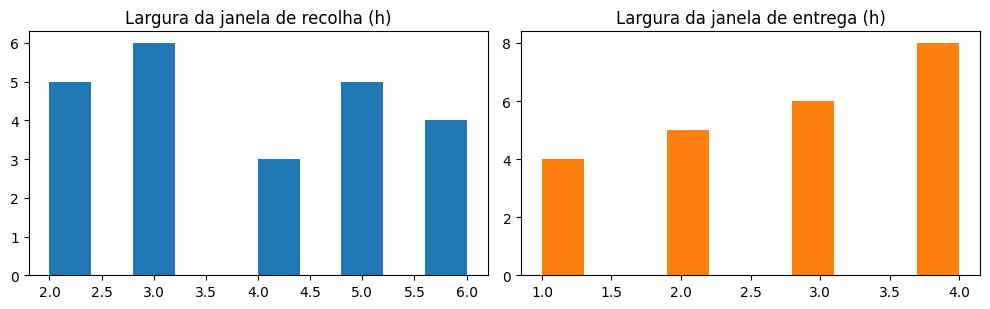

In [ ]:
it["w_pickup_h"] = (it.availability_end - it.availability_start).dt.total_seconds() / 3600
it["w_deliv_h"] = (it.delivery_end - it.delivery_start).dt.total_seconds() / 3600
display(it[["w_pickup_h", "w_deliv_h", "travel_min"]].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(it.w_pickup_h, bins=10, color="tab:blue")
ax[0].set_title("Largura da janela de recolha (h)")
ax[1].hist(it.w_deliv_h, bins=10, color="tab:orange")
ax[1].set_title("Largura da janela de entrega (h)")
plt.tight_layout()
plt.show()

**O que vemos:** As janelas de recolha têm em média cerca de **4 horas** e as de entrega cerca de **3 horas**. O tempo de viagem entre produtor e cliente é, em média, de cerca de **55 minutos**. As janelas são portanto mais largas do que uma viagem, mas não tanto que o veículo possa fazer o que quiser: a ordem das paragens importa e é aí que os algoritmos de pesquisa e o CSP têm trabalho a fazer.

### 3.5 Linha temporal
Para perceber como os pedidos se distribuem no tempo, desenhamos uma linha por item: a barra **azul** é a janela de recolha e a **laranja** a de entrega. Ordenamos os itens pela abertura da janela de recolha.

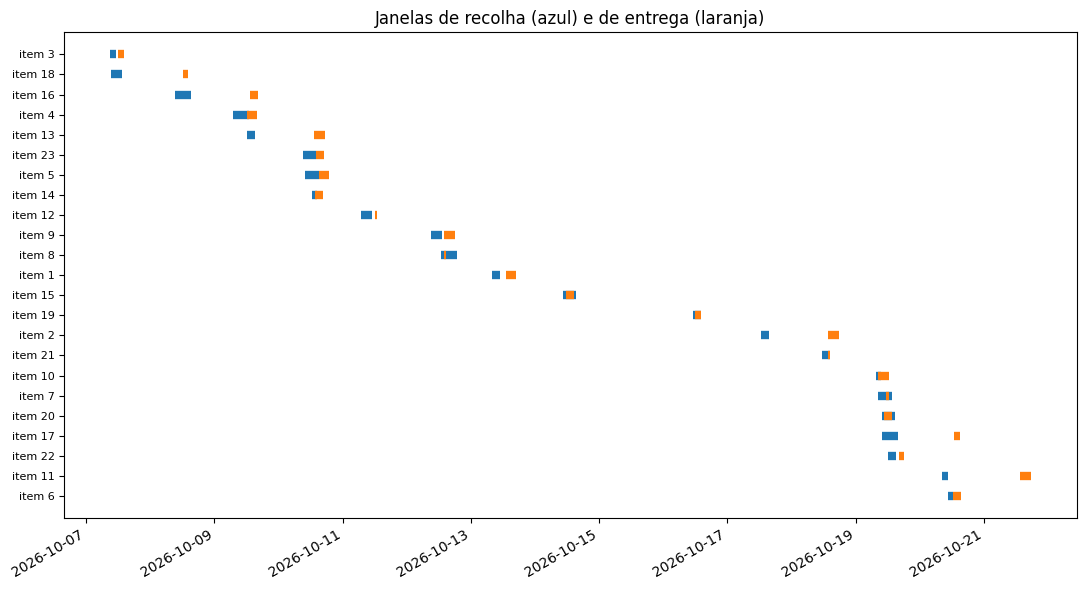

In [ ]:
s = it.sort_values("availability_start").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6))
for i, r in s.iterrows():
    ax.hlines(i, r.availability_start, r.availability_end, color="tab:blue", lw=6)
    ax.hlines(i, r.delivery_start, r.delivery_end, color="tab:orange", lw=6)
ax.set_yticks(range(len(s)))
ax.set_yticklabels([f"item {x}" for x in s.order_item_id], fontsize=8)
ax.invert_yaxis()
ax.set_title("Janelas de recolha (azul) e de entrega (laranja)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**O que vemos:** Os pedidos estão **espalhados ao longo de duas semanas** (7 a 21 de outubro) e as janelas de itens diferentes raramente se sobrepõem. Isto significa que:
- o mesmo veículo pode servir muitos pedidos seguidos, **esperando** entre eles;
- só há conflito real nos dias em que várias janelas coincidem;
- esperar é inevitável, e no nosso modelo o tempo de espera **não tem custo** (o custo é só a distância percorrida).

### 3.6 Quantos pedidos estão ativos ao mesmo tempo?
Contamos o máximo de itens que, num mesmo instante, já abriram a janela de recolha e ainda não terminaram a entrega. É uma medida da **pressão sobre a frota**: se for baixo, poucos veículos chegam.

In [ ]:
# nº máximo de itens "em curso" ao mesmo tempo (da abertura da recolha ao fim da entrega)
events = []
for _, r in it.iterrows():
    events += [(r.availability_start, +1), (r.delivery_end, -1)]
events.sort()

cur = peak = 0
for _, d in events:
    cur += d
    peak = max(peak, cur)

print("Pico de itens com janela aberta em simultâneo:", peak)
print("Período total:", it.availability_start.min(), "->", it.delivery_end.max())
print("Dias com recolhas:", it.availability_start.dt.date.nunique())

Pico de itens com janela aberta em simultâneo: 5
Período total: 2026-10-07 09:00:00 -> 2026-10-21 17:30:00
Dias com recolhas: 13


**Conclusão.** No pior momento há apenas **5 itens** com a janela aberta ao mesmo tempo, num total de 23 e ao longo de 13 dias com recolhas. É um pico baixo, o que sugere que a concorrência entre pedidos é limitada e que só os períodos mais carregados exigem os dois veículos.

### 3.7 Coerência com a data da encomenda
Cada encomenda tem a data em que foi feita (`order_datetime`). Verificamos se as janelas de recolha começam depois dessa data, como seria lógico.

In [ ]:
# coerência com a data da encomenda (informativo)
early = it.availability_start < it.order_datetime
print(f"Itens cuja janela de recolha começa ANTES de a encomenda ser feita: {int(early.sum())} de {len(it)}")

Itens cuja janela de recolha começa ANTES de a encomenda ser feita: 13 de 23


**Observação:** 13 dos 23 itens têm a janela de recolha a começar **antes** da data da encomenda. No mundo real isto seria impossível, mas o dataset é **sintético** e esta data não faz parte das restrições do problema. Por isso usamos apenas as janelas de cada item e **ignoramos `order_datetime`** no planeamento.

## 4. Pesos vs. capacidades

Os veículos têm uma capacidade máxima em kg. Será que a **capacidade** é uma restrição importante neste dataset? Comparamos o peso dos pedidos com a capacidade da frota.

### 4.1 Peso dos itens vs. capacidade dos veículos
Mostramos os veículos, as estatísticas do peso dos itens e dois rácios: o maior item contra o veículo mais pequeno, e o peso total de todos os itens contra o veículo mais pequeno. O gráfico compara o peso de cada item (escala logarítmica) com a menor capacidade (linha vermelha).

,vehicle_id,plate,center_id,capacity_kg,refrigerated,avg_speed_kmh
0,1,ZG-06-DP,1,1444.7,0,57.8
1,2,TY-74-YA,1,1009.8,0,59.5


Capacidade total da frota: 2454.5 kg
Capacidade do centro: [3232.9] kg

Peso dos itens (kg):


,peso
count,23.00
mean,10.82
std,8.08
min,0.90
25%,3.19
50%,9.00
75%,17.80
max,24.60


Peso total de todos os itens: 249.0 kg
Maior item: 24.6 kg  |  menor capacidade: 1009.8 kg
Rácio maior item / menor capacidade: 2.4%
Rácio peso total / menor capacidade: 24.7%


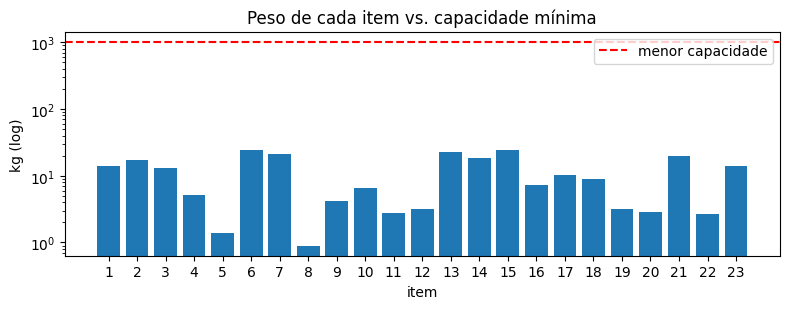

In [ ]:
veh = dfs["vehicles"]
display(veh)
print(f"Capacidade total da frota: {veh.capacity_kg.sum():.1f} kg")
print("Capacidade do centro:", dfs["collection_centers"].capacity_kg.tolist(), "kg")

print("\nPeso dos itens (kg):")
display(it.weight_kg.describe().round(2).to_frame("peso"))
print(f"Peso total de todos os itens: {it.weight_kg.sum():.1f} kg")
print(f"Maior item: {it.weight_kg.max():.1f} kg  |  menor capacidade: {veh.capacity_kg.min():.1f} kg")
print(f"Rácio maior item / menor capacidade: {it.weight_kg.max() / veh.capacity_kg.min():.1%}")
print(f"Rácio peso total / menor capacidade: {it.weight_kg.sum() / veh.capacity_kg.min():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(it.order_item_id.astype(str), it.weight_kg)
ax.axhline(veh.capacity_kg.min(), color="red", ls="--", label="menor capacidade")
ax.set_yscale("log")
ax.set_xlabel("item")
ax.set_ylabel("kg (log)")
ax.legend()
ax.set_title("Peso de cada item vs. capacidade mínima")
plt.tight_layout()
plt.show()

**Conclusão.** O peso total de todos os itens é cerca de **249 kg** e o maior item pesa **24,6 kg**, contra capacidades de 1010 kg e 1445 kg. O maior item ocupa apenas **2,4%** do veículo mais pequeno e mesmo todos os itens juntos não chegam a **25%** da sua capacidade. Todas as barras do gráfico ficam muito abaixo da linha vermelha.

**A capacidade nunca é a restrição ativa neste dataset.** Vamos mantê-la no modelo, porque o dataset maior pode ser diferente, mas aqui o que realmente condiciona as rotas são as **janelas temporais**.

### 4.2 Como está distribuído o peso
Vemos o peso total de cada encomenda e de cada produtor (local de recolha), e confirmamos que todos os produtos têm produtor e peso unitário definidos. Vemos também em que unidades se vendem os produtos, porque isso afeta o cálculo do peso.

In [ ]:
# peso por encomenda e por produtor
display(it.groupby("order_id").weight_kg.sum().round(1).rename("kg por encomenda").to_frame().T)
display(it.groupby("pickup_loc").weight_kg.agg(["count", "sum"]).round(1).rename(
    columns={"count": "itens", "sum": "kg"}).T)
print("Produtos sem produtor/peso unitário:", int(it.unit_weight_kg.isna().sum()))
print("Unidades de venda:", it.unit.value_counts().to_dict())

order_id,1,2,3,4,5,6,7,8,9,10
kg por encomenda,31.3,18.3,48.0,13.5,3.2,22.9,49.9,22.6,2.9,36.3


pickup_loc,1,2,3,4,5
itens,5.0,3.0,7.0,7.0,1.0
kg,65.4,35.5,73.7,60.4,14.0


Produtos sem produtor/peso unitário: 0
Unidades de venda: {'kg': 17, 'unit': 6}


**O que vemos:**
- O peso está repartido de forma irregular: há produtores com muito mais carga do que outros (o que tem mais concentra cerca de **74 kg em 7 itens**).
- Seis itens são vendidos **à unidade** e 17 **ao quilo**, o que confirma que é necessário multiplicar a quantidade pelo peso unitário para obter o peso real.
- Nenhum produto tem peso ou produtor em falta.

## 5. Mapa das paragens

Onde ficam o centro de recolha, os produtores e os locais de entrega? A geografia influencia diretamente o custo das rotas.

### 5.1 Mapa
Desenhamos todas as paragens pelas suas coordenadas: o **centro de recolha** (estrela vermelha), os **produtores** (círculos verdes) e os **locais de entrega** (quadrados azuis). O número ao lado de cada ponto é o `location_id`, o mesmo usado na matriz de distâncias. Mostramos também os locais com coordenadas idênticas.

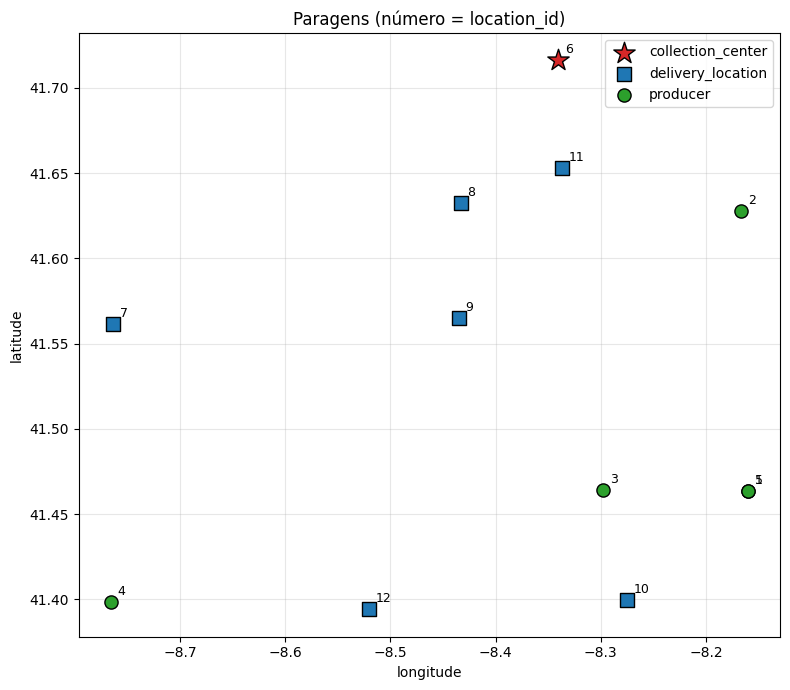

Locais com coordenadas idênticas:


,location_id,location_type,name,municipality,latitude,longitude
0,1,producer,Hortas Valente,Fafe,41.463574,-8.15984
4,5,producer,Pomar Antunes,Fafe,41.463574,-8.15984


In [ ]:
colors = {"producer": "tab:green", "collection_center": "tab:red", "delivery_location": "tab:blue"}
markers = {"producer": "o", "collection_center": "*", "delivery_location": "s"}

fig, ax = plt.subplots(figsize=(8, 7))
for t, g in loc.groupby("location_type"):
    ax.scatter(g.longitude, g.latitude, c=colors[t], marker=markers[t],
               s=260 if t == "collection_center" else 90, label=t, edgecolor="k", zorder=3)
    for _, r in g.iterrows():
        ax.annotate(str(r.location_id), (r.longitude, r.latitude), xytext=(5, 5),
                    textcoords="offset points", fontsize=9)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.grid(alpha=.3)
ax.legend()
ax.set_title("Paragens (número = location_id)")
plt.tight_layout()
plt.show()

dup = loc[loc.duplicated(["latitude", "longitude"], keep=False)]
print("Locais com coordenadas idênticas:")
display(dup[["location_id", "location_type", "name", "municipality", "latitude", "longitude"]])

**O que vemos:** São 12 paragens: 1 centro, 5 produtores e 6 locais de entrega, espalhados pelo distrito de Braga sem uma estrutura óbvia (não formam uma estrela nem uma linha). As rotas vão por isso cruzar várias zonas. Os produtores **1 e 5 têm as mesmas coordenadas**, o que explica a distância 0 entre eles na matriz.

### 5.2 Distâncias a partir do centro
Como todos os veículos partem e regressam ao centro de recolha, vemos a que distância fica cada paragem dele, e qual é a maior distância entre dois pontos quaisquer.

In [ ]:
# distâncias a partir do centro de recolha
depot = int(loc[loc.location_type == "collection_center"].location_id.iloc[0])
from_depot = dm[dm.origin_location_id == depot].merge(
    loc[["location_id", "location_type", "name"]],
    left_on="destination_location_id", right_on="location_id")
display(from_depot[["location_id", "location_type", "name", "distance_km", "duration_min"]]
        .sort_values("distance_km").reset_index(drop=True).round(1))
print(f"Distância máxima entre dois locais: {dm.distance_km.max():.1f} km ({dm.duration_min.max():.0f} min)")

,location_id,location_type,name,distance_km,duration_min
0,11,delivery_location,Casa 5,9.1,12.2
1,8,delivery_location,Casa 2,15.7,21.0
2,2,producer,Quinta Leite,22.7,30.2
3,9,delivery_location,Casa 3,24.1,32.2
4,3,producer,Quinta Morais,36.7,48.9
5,5,producer,Pomar Antunes,41.4,55.2
6,1,producer,Hortas Valente,41.4,55.2
7,10,delivery_location,Casa 4,46.3,61.7
8,12,delivery_location,Casa 6,50.4,67.3
9,7,delivery_location,Mercado Municipal 1,50.9,67.9


Distância máxima entre dois locais: 72.8 km (97 min)


**O que vemos:** As paragens ficam entre cerca de **9 km** e **65 km** do centro, e a maior distância entre dois pontos quaisquer é de **72,8 km** (97 minutos). Com estas distâncias, uma ida e volta pode chegar aos 130 km, por isso o custo total das rotas é dominado por **para onde** se vai e não por **quantas** paragens se fazem. É por isso que a **ordem das paragens** tem tanto efeito no custo final.

## 6. Conclusões da EDA

**Qualidade dos dados.** Não há valores nulos nem duplicados, todas as chaves primárias são únicas e não há referências órfãs. A matriz de distâncias está completa (12·11 = 132 pares), é simétrica, não tem valores negativos e **cumpre a desigualdade triangular**, pelo que as heurísticas baseadas em distâncias diretas são admissíveis.

**Janelas temporais.** As 23 linhas de `order_items` têm janelas válidas e com a regra do armazém **um item (o 8) é impossível sozinho**. Os itens estão espalhados por duas semanas (7 a 21 de outubro), com janelas de poucas horas e uma viagem típica de ~55 min. Em consequência, **um veículo tem de esperar horas ou dias entre pedidos distantes no tempo**, e só há concorrência real quando as janelas coincidem (pico de 5 itens abertos em simultâneo).

**Pesos vs. capacidades.** O peso total de todos os itens é ~249 kg e o maior item pesa 24,6 kg, contra capacidades de 1010 e 1445 kg. **A capacidade nunca é a restrição ativa neste dataset**; o que condiciona as rotas são as janelas temporais. Convém manter a restrição no modelo, porque o dataset grande pode ser diferente. Seis itens são vendidos à unidade, por isso o peso tem de ser `quantity × unit_weight_kg`.

**Mapa e distâncias.** Os produtores 1 e 5 partilham coordenadas (distância 0 entre eles). Os locais ficam entre 9 e 65 km do centro, com um máximo de 72,8 km entre dois pontos.

### O que o modelo do agente tem de ter em conta
- Os `location_id` (usados na matriz) **não coincidem** com `producer_id`, `customer_id` ou `center_id`: é preciso mapear através de `locations.csv`.
- Há 1 encomenda `delivered` (3 itens). Já foi entregue, por isso fica fora do planeamento (restam **20 pedidos**).
- 13 dos 23 itens têm a janela de recolha antes da data da encomenda: o dataset é sintético e esta data não restringe o planeamento, por isso usamos apenas as janelas de cada item.
- O tempo de viagem da matriz corresponde a 45 km/h, mas os veículos têm velocidades médias de 58–60 km/h; é preciso decidir qual usar e justificá-lo no relatório.
- Nenhum produto indica necessidade de refrigeração, logo o campo `refrigerated` não é usado.
- O tempo de espera não tem custo: o custo de uma rota é a distância percorrida.